In [3]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from matplotlib import rcParams
import plotting_functions

In [2]:

# === Settings ===
base = 9
matplotlib.rcParams.update({
    'font.size': base,
    'axes.labelsize': base,
    'axes.titlesize': base,
    'xtick.labelsize': base,
    'ytick.labelsize': base,
    'legend.fontsize': base,
    'font.family': 'Arial',
})
ms = 6
lw = 2

In [9]:

# Load data
y_sim_H3N2_NA = np.loadtxt("/Users/edwin/Documents/1-work_Riverside/John_Barton/2-Flu/cluster/smooth_H3N2_NA/results/last_results/y_sim_H3N2_NA.txt")
y_sim_H3N2_HA = np.loadtxt("/Users/edwin/Documents/1-work_Riverside/John_Barton/2-Flu/cluster/smooth_H3N2_HA/results/last_results/y_sim_H3N2_HA.txt")
y_sim_H1N1_NA = np.loadtxt("/Users/edwin/Documents/1-work_Riverside/John_Barton/2-Flu/cluster/smooth_H1N1_NA/results/last_results/y_sim_H1N1_NA.txt")
y_sim_H1N1_HA = np.loadtxt("/Users/edwin/Documents/1-work_Riverside/John_Barton/2-Flu/cluster/smooth_H1N1_HA/results/last_results/y_sim_H1N1_HA.txt")


# Processed vectors
y_sim_H3N2_HA_2012 = plotting_functions.trim_and_concat(y_sim_H3N2_HA, 120, 36)
y_sim_H3N2_NA_2012 = plotting_functions.trim_and_concat(y_sim_H3N2_NA, 120, 36)
y_sim_H1N1_HA_2012 = plotting_functions.trim_and_concat(y_sim_H1N1_HA, 120, 32)
y_sim_H1N1_NA_2012 = plotting_functions.trim_and_concat(y_sim_H1N1_NA, 120, 32)


# Group labels: 6, 9, 12 repeated for each chunk
df1 = plotting_functions.create_dataframe(y_sim_H3N2_HA_2012, "a. H3N2-HA")
df2 = plotting_functions.create_dataframe(y_sim_H3N2_NA_2012, "c. H3N2-NA")
df3 = plotting_functions.create_dataframe(y_sim_H1N1_HA_2012, "b. H1N1-HA")
df4 = plotting_functions.create_dataframe_irregular(y_sim_H1N1_NA_2012, "d. H1N1-NA")

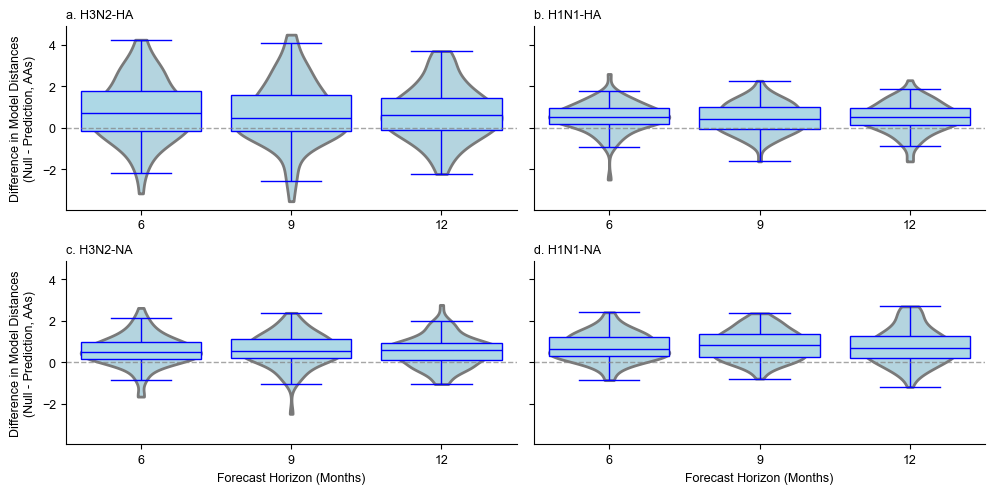

In [10]:
# Consistent fill color and blue borders
fill_color = "lightblue"     # Fill for violins and boxes
border_color = "blue"   # Blue borders and medians

# Set up figure and axes
fig, axes = plt.subplots(2, 2, figsize=(10, 5), sharey=True)
axes = axes.flatten()
# Combine all for plotting
dfs = [df1, df3, df2, df4]

# Plotting
for ax, df in zip(axes, dfs):
    # Violin plot
    sns.violinplot(
        x="Horizon", y="Value", data=df, ax=ax, inner=None,
        color=fill_color, linewidth=lw, cut=0
    )

    # Box plot overlay with blue borders
    sns.boxplot(
        x="Horizon", y="Value", data=df, ax=ax,
        boxprops=dict(facecolor=fill_color, edgecolor=border_color, linewidth=1.0),
        whiskerprops=dict(linewidth=1.0, color=border_color),
        capprops=dict(linewidth=1.0, color=border_color),
        medianprops=dict(color=border_color, linewidth=1.0),
        showcaps=True, showfliers=False
    )

    # Add horizontal line at y=0
    ax.axhline(0.0, linestyle='--', linewidth=1, color='gray', alpha=0.7)

    # Format axes
    ax.set_title(df["Label"].iloc[0], loc='left')
    ax.set_xticks([0, 1, 2])
    ax.set_xticklabels(["6", "9", "12"])
    ax.set_xlabel("")
    ax.set_ylabel("")
    sns.despine(ax=ax)  # Remove top and right spines

# Set common labels
axes[0].set_ylabel("Difference in Model Distances\n(Null - Prediction, AAs)")
axes[2].set_ylabel("Difference in Model Distances\n(Null - Prediction, AAs)")
axes[2].set_xlabel("Forecast Horizon (Months)")
axes[3].set_xlabel("Forecast Horizon (Months)")

# Final layout
plt.tight_layout(pad=1)

# Save or display
#plt.savefig("EMD_vs_horizon_all_proteins_2012_Py.pdf", dpi=300, bbox_inches='tight')
plt.show()